# Практическое занятие №9
**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»

**Цель работы:** изучить устройство искусственной нейронной сети (нейрон, слой, функции активации, функции потерь), алгоритм обратного распространения ошибки и стохастический градиентный спуск; реализовать многослойный персептрон «с нуля» на тензорах PyTorch и применить его к задачам классификации и регрессии. Дополнительно (по теме, указанной в заголовке методических указаний) реализованы алгоритмы кластеризации k-means и k-means++.

Ниже — разбор примера из методических указаний («Текущий контроль 5_1»), затем — решение задания.

# Создание нейронной сети на Torch

In [1]:
import torch
import numpy as np

torch.manual_seed(0)   # воспроизводимость случайной инициализации
np.random.seed(0)

## Нейрон

<img src="Текущий контроль 5_1/img/Neuron.png" width=300, heigth=300>

In [2]:
# Создание класса нейрон. weights - веса связей, bias - порог, input - вектор сигналов, подающихся на нейрон

class Neuron:
  def __init__(self, weights, bias):
    self.weights = weights
    self.bias = bias
  
  def forward(self, input):
    return torch.dot(self.weights, input) + self.bias # dot - скалярное произведение векторов

In [3]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])

weights = torch.tensor([0.2, 0.8, -0.5, 1.0])
bias = 2.0

neuron = Neuron(weights, bias)
neuron.forward(inputs)

tensor(4.8000)

## Слой

<img src="Текущий контроль 5_1/img/Layer.png" width=300, heigth=300>

In [4]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases
  
  def forward(self, input):
    return torch.mv(self.weights, input) + self.biases #mv - произведение вектора на матрицу

In [5]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])
weights = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])

biases = torch.tensor([2.0, 3.0, 0.5])

layer = Layer(weights, biases)
layer.forward(inputs)

tensor([4.8000, 1.2100, 2.3850])

## Слой (batch)
обработка партиями

In [6]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases
  
  def forward(self, inputs):
    return inputs @ self.weights.T + self.biases # провизведение матриц

In [7]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
weights1 = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])
biases1 = torch.tensor([2.0, 3.0, 0.5])

weights2 = torch.tensor([[.1, -.14, .5], [-.5, .12, -.33], [-.44, .73, -.13]])
biases2 = torch.tensor([-1, 2, -.5])

layer1 = Layer(weights1, biases1)
hidden_input = layer1.forward(inputs1)

layer2 = Layer(weights2, biases2)
output = layer2.forward(hidden_input)
output

tensor([[ 0.5031, -1.0419, -2.0388],
        [ 0.2434, -2.7332, -5.7633],
        [-0.9931,  1.4125, -0.3565]])

## Слой (случ. иниц)

In [8]:
class Layer:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons)
    self.biases = torch.zeros(n_neurons)
  
  def forward(self, inputs):
    return inputs @ self.weights + self.biases

In [9]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 6)
out = layer.forward(inputs1)
out

tensor([[ 3.7540e+00, -2.6253e+00,  1.8003e+00, -2.1161e+00,  4.4288e+00,
         -7.8897e-01],
        [ 1.1762e-02, -1.3648e+01,  3.2189e+00, -2.3703e+00,  6.3018e+00,
         -3.1768e+00],
        [-2.1916e-01, -1.1401e+00,  6.7182e-01,  1.8693e-01,  6.3727e+00,
          5.6879e+00]])

## Функции активации

<img src="Текущий контроль 5_1/img/Act.png" width=500, heigth=300>

Функция активации ReLU:
![](https://wikimedia.org/api/rest_v1/media/math/render/svg/f4353f4e3e484130504049599d2e7b040793e1eb)
Функцию активации softmax:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/6d7500d980c313da83e4117da701bf7c8f1982f5)

In [10]:
# RELU
class ReLU:
  def forward(self, inputs):
    return inputs.clip(min=0)    # заменить отрицательные числа нулями

In [11]:
ReLU().forward(out)

tensor([[3.7540, 0.0000, 1.8003, 0.0000, 4.4288, 0.0000],
        [0.0118, 0.0000, 3.2189, 0.0000, 6.3018, 0.0000],
        [0.0000, 0.0000, 0.6718, 0.1869, 6.3727, 5.6879]])

In [12]:
class Softmax:
  def forward(self, inputs):
    exp = torch.exp(inputs)
    probs = exp / exp.sum(dim=1, keepdim=True)
    return probs 

In [13]:
Softmax().forward(out)

tensor([[3.2044e-01, 5.4358e-04, 4.5425e-02, 9.0447e-04, 6.2928e-01, 3.4102e-03],
        [1.7699e-03, 2.0688e-09, 4.3732e-02, 1.6347e-04, 9.5426e-01, 7.2974e-05],
        [9.0737e-04, 3.6127e-04, 2.2117e-03, 1.3619e-03, 6.6159e-01, 3.3356e-01]])

## Функции потерь

Функция потерь MSE:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/e258221518869aa1c6561bb75b99476c4734108e)
Функция потерь Categorical Cross-Entropy:

<img src="https://i.ibb.co/93gy1dN/Screenshot-9.png" width="200">


In [14]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 1)
out = layer.forward(inputs1)
out

tensor([[8.0400],
        [8.6332],
        [5.8585]])

In [15]:
# Среднеквадратичная ошибка
class MSELoss:
  def forward(self, y_pred, y_true):
    return torch.mean(torch.pow(out - y_true, 2))

In [16]:
y_true = torch.tensor([2, 3, 4]).view(-1, 1)
MSELoss().forward(out, y_true)

tensor(23.8892)

In [17]:
# Кроссэнтропия
class CategoricalCrossentropyLoss:
  def forward(self, y_pred, y_true):
    correct_conf = y_pred.gather(dim=1, index=y_true.view(-1, 1))
    neglog = -torch.log(correct_conf)
    return torch.mean(neglog)

In [18]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 3)
out = layer.forward(inputs1)
out = Softmax().forward(out)
out

tensor([[9.5370e-01, 5.3685e-05, 4.6243e-02],
        [9.0394e-02, 9.0434e-01, 5.2685e-03],
        [1.7138e-01, 5.9420e-03, 8.2267e-01]])

In [19]:
y_true = torch.tensor([1, 0, 0])
CategoricalCrossentropyLoss().forward(out, y_true)

tensor(4.6666)

## Оптимизация SGD (стохастический градиентный спуск)

#### Модифицируем класс Neuron
    Сделаем так, чтобы веса нейрона инициализировались из стандартного нормального распределения:

In [20]:
# Сформируем случайную задачу регркессии
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

Граф вычислений для решения задачи:
<img src="Текущий контроль 5_1/img/back.png" width=700, heigth=700>

In [21]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs)
    self.bias = torch.randn(1)
  
  def forward(self, input):
    self.input = input
    return torch.dot(self.weights, input) + self.bias

  def backward(self, dvalue):
    self.dweights = dvalue * self.input
    self.dinput = dvalue * self.weights
    self.dbias = dvalue


class Loss:    #класс вычисления ошибок
  def forward(self, y_pred, y_true):
    return (y_pred - y_true) ** 2

  def backward(self, y_pred, y_true):
    self.dinput = 2 * (y_pred - y_true)


In [22]:
neuron = Neuron(4)
loss = Loss()

lr = 0.1

losses = []
for epoch in range(100):
  for x_example, y_example in zip(X, y):
    y_pred = neuron.forward(x_example)
    l = loss.forward(y_pred, y_example)
    losses.append(l)

    loss.backward(y_pred, y_example)
    neuron.backward(loss.dinput)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbias
  

In [23]:
neuron.weights, neuron.bias

(tensor([20.4924, 34.1698, 67.6242, 87.9235]), tensor([0.5000]))

#### Используем пакетный градиентный спуск (batch SGD + neuron)

In [24]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs, requires_grad=False)
    self.bias = torch.tensor(0.0, requires_grad=False)
  
  def forward(self, inputs):
    self.inputs = inputs
    return X @ self.weights.T + self.bias

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T.mv(dvalues)
      self.dbiases = dvalues.sum()


class MSELossNeuron:
  def forward(self, y_pred, y_true):
    return torch.mean((y_pred - y_true) ** 2)

  def backward(self, y_pred, y_true):
    with torch.no_grad():
      self.dinputs = 2 * (y_pred - y_true) / len(y_pred)

Вычисления для решения задачи:
    <img src="Текущий контроль 5_1/img/back1.png" width=700, heigth=700>
    <img src="Текущий контроль 5_1/img/back2.png" width=700, heigth=700>

In [25]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

In [26]:
neuron = Neuron(4)
loss = MSELossNeuron()

lr = 0.1

for epoch in range(100):
    y_pred = neuron.forward(X)
    l = loss.forward(y_pred, y)
    loss.backward(y_pred, y)
    neuron.backward(loss.dinputs)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbiases
print(f'epoch {epoch} mean loss {l.mean()}')

epoch 99 mean loss 4.2449030401847665e-10


C:\Users\bogdi\AppData\Local\Temp\ipykernel_67000\2213006203.py:8: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4323.)
  return X @ self.weights.T + self.bias


In [27]:
neuron.weights, coef

(tensor([97.3016, 10.0003,  6.2036, 31.7898]),
 array([97.30166328, 10.0002677 ,  6.20358205, 31.78978693]))

### Разные варианты веализации рейросети

In [28]:
class Dense:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons, requires_grad=False)
    self.biases = torch.zeros(n_neurons, requires_grad=False)
  
  def forward(self, inputs):
    self.inputs = inputs
    self.output = self.inputs @ self.weights + self.biases
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T @ dvalues
      self.dbiases = torch.sum(dvalues, dim=0)
      self.dinputs = dvalues @ self.weights.T

class Activation_ReLU:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs.clip(min=0)
    return self.output
  
  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()
      self.dinputs[self.inputs <= 0] = 0

class Activation_Linear:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()

class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = sample_losses.mean()
    return data_loss

class MSELoss(Loss):
  def forward(self, y_pred, y_true):
    sample_losses = torch.mean((y_true - y_pred) ** 2, dim=1)
    return sample_losses

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      self.dinputs = -2 * (y_true - dvalues) / len(dvalues)


In [29]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [30]:
fc1 = Dense(4, 1)
loss = MSELoss()
lr = 0.1

for epoch in range(100):
  out = fc1.forward(X)
  data_loss = loss.calculate(out, y.view(-1, 1))
  print(f'epoch {epoch} mean loss {data_loss}')
  loss.backward(out, y.view(-1, 1))
  fc1.backward(loss.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

epoch 0 mean loss 9975.3095703125
epoch 1 mean loss 6851.5029296875
epoch 2 mean loss 4738.9775390625
epoch 3 mean loss 3299.594970703125
epoch 4 mean loss 2311.748046875
epoch 5 mean loss 1629.08837890625
epoch 6 mean loss 1154.2271728515625
epoch 7 mean loss 821.86474609375
epoch 8 mean loss 587.890625
epoch 9 mean loss 422.290771484375
epoch 10 mean loss 304.4991455078125
epoch 11 mean loss 220.32847595214844
epoch 12 mean loss 159.92898559570312
epoch 13 mean loss 116.41988372802734
epoch 14 mean loss 84.96756744384766
epoch 15 mean loss 62.15829086303711
epoch 16 mean loss 45.56879425048828
epoch 17 mean loss 33.471195220947266
epoch 18 mean loss 24.628097534179688
epoch 19 mean loss 18.149951934814453
epoch 20 mean loss 13.394935607910156
epoch 21 mean loss 9.8984956741333
epoch 22 mean loss 7.323322772979736
epoch 23 mean loss 5.4239182472229
epoch 24 mean loss 4.021069526672363
epoch 25 mean loss 2.983703374862671
epoch 26 mean loss 2.215764045715332
epoch 27 mean loss 1.646690

In [31]:
fc1.weights, coef

(tensor([[94.5431],
         [41.5953],
         [23.1255],
         [30.7874]]),
 array([94.54309704, 41.59533146, 23.1254953 , 30.7874098 ]))

In [32]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [33]:
X = torch.linspace(-1, 1, 100).view(-1, 1)
y = X.pow(2) + 0.2 * torch.rand(X.size()) 

In [34]:
fc1 = Dense(1, 10)
relu1 = Activation_ReLU()
fc2 = Dense(10, 1)

loss = MSELoss()
lr = 0.02

ys = []
for epoch in range(2001):
  out = fc1.forward(X)
  out = relu1.forward(out)
  out = fc2.forward(out)


  data_loss = loss.calculate(out, y)
  if epoch % 200 == 0:
    print(f'epoch {epoch} mean loss {data_loss}')
    ys.append(out)
  loss.backward(out, y)
  fc2.backward(loss.dinputs)
  relu1.backward(fc2.dinputs)
  fc1.backward(relu1.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

  fc2.weights -= lr * fc2.dweights
  fc2.biases -= lr * fc2.dbiases 

epoch 0 mean loss 6.269287109375
epoch 200 mean loss 0.0198349766433239
epoch 400 mean loss 0.00897260196506977
epoch 600 mean loss 0.008320045657455921
epoch 800 mean loss 0.007886526174843311


epoch 1000 mean loss 0.007451597601175308


epoch 1200 mean loss 0.007105284370481968


epoch 1400 mean loss 0.006873094942420721
epoch 1600 mean loss 0.006659791339188814
epoch 1800 mean loss 0.006507085636258125
epoch 2000 mean loss 0.00637090764939785


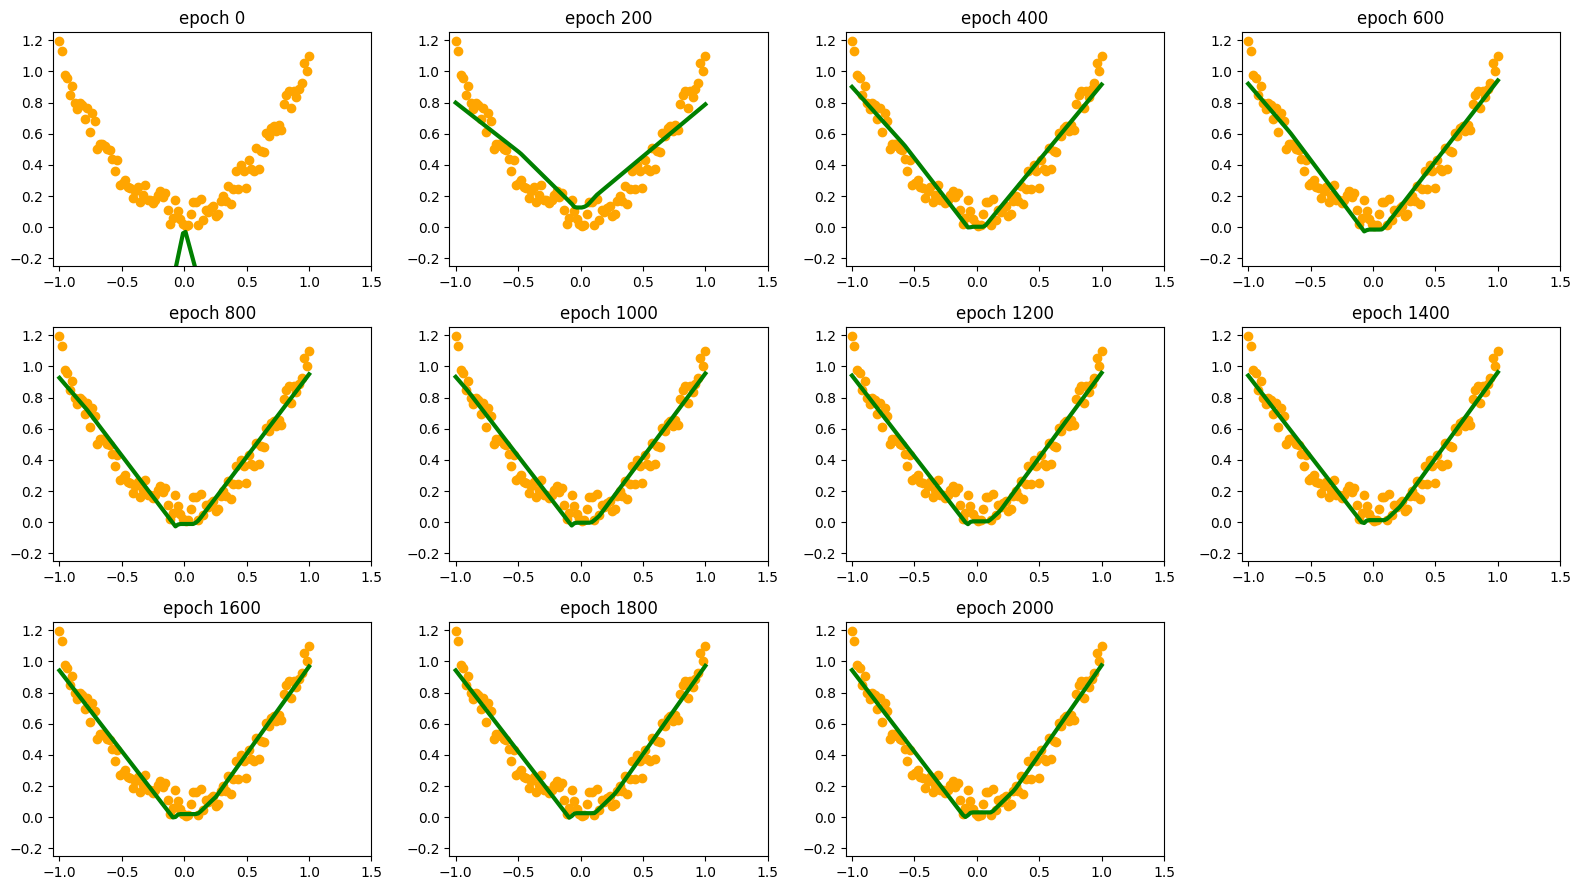

In [35]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3, 4, figsize=(16, 9))
for i, (ax, y_) in enumerate(zip(axs.ravel(), ys)):
  ax.set_title(f'epoch {i * 200}')
  ax.scatter(X.numpy(), y.numpy(), color = "orange")
  ax.plot(X.numpy(), y_.numpy(), 'g-', lw=3)
  ax.set_xlim(-1.05, 1.5)
  ax.set_ylim(-0.25, 1.25)
axs.ravel()[-1].axis('off')
plt.tight_layout()

---
# Решение задания

## Часть 1. Многослойный персептрон и обратное распространение ошибки

Расширим классы из примера до полноценного многослойного персептрона для **многоклассовой классификации**:
* `Dense` — полносвязный слой с инициализацией He ($w \sim \mathcal{N}(0, 2/n_{in})$), чтобы сигнал не затухал и не «взрывался»;
* `ReLU` — функция активации скрытых слоёв;
* `SoftmaxCrossEntropy` — объединённые softmax и категориальная кросс-энтропия: градиент по входам этого блока
  имеет простой вид $\dfrac{\partial L}{\partial z} = \dfrac{1}{N}(\hat{p} - y_{one\text{-}hot})$, а вычисление устойчиво к переполнению
  (из логитов вычитается максимум);
* оптимизаторы `SGD` (с инерцией, momentum) и `Adam`;
* `MLP` — последовательность слоёв с методами `forward`, `backward` и обучением мини-батчами.

**Обратное распространение ошибки.** Для слоя $Z = XW + b$ при известном $G = \partial L / \partial Z$:
$\dfrac{\partial L}{\partial W} = X^T G$, $\dfrac{\partial L}{\partial b} = \sum_i G_i$, $\dfrac{\partial L}{\partial X} = G W^T$;
для ReLU градиент пропускается только там, где вход был положителен.

In [36]:
import time
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

plt.rcParams['figure.figsize'] = (9, 5)
torch.manual_seed(42); np.random.seed(42)


class Dense:
    """Полносвязный слой: Z = X @ W + b."""
    def __init__(self, n_inputs, n_neurons):
        self.weights = torch.randn(n_inputs, n_neurons) * np.sqrt(2.0 / n_inputs)   # инициализация He
        self.biases = torch.zeros(n_neurons)

    def forward(self, inputs):
        self.inputs = inputs
        return inputs @ self.weights + self.biases

    def backward(self, dvalues):
        self.dweights = self.inputs.T @ dvalues
        self.dbiases = dvalues.sum(dim=0)
        self.dinputs = dvalues @ self.weights.T
        return self.dinputs

    def params(self):
        return [(self.weights, 'dweights'), (self.biases, 'dbiases')]


class ReLU:
    def forward(self, inputs):
        self.inputs = inputs
        return inputs.clip(min=0)

    def backward(self, dvalues):
        self.dinputs = dvalues.clone()
        self.dinputs[self.inputs <= 0] = 0
        return self.dinputs

    def params(self):
        return []


class SoftmaxCrossEntropy:
    """Softmax + категориальная кросс-энтропия с общим (простым и устойчивым) градиентом."""
    def forward(self, logits, y_true):
        exp = torch.exp(logits - logits.max(dim=1, keepdim=True).values)
        self.probs = exp / exp.sum(dim=1, keepdim=True)
        self.y_true = y_true
        correct = self.probs[torch.arange(len(y_true)), y_true].clamp(min=1e-12)
        return -torch.log(correct).mean()

    def backward(self):
        n = len(self.y_true)
        self.dinputs = self.probs.clone()
        self.dinputs[torch.arange(n), self.y_true] -= 1
        self.dinputs /= n
        return self.dinputs


class SGD:
    """Стохастический градиентный спуск с инерцией: v <- mu*v - lr*g;  w <- w + v."""
    def __init__(self, lr=0.1, momentum=0.0):
        self.lr, self.momentum, self.v = lr, momentum, {}

    def step(self, layers):
        for layer in layers:
            for p, gname in layer.params():
                g = getattr(layer, gname)
                v = self.v.get(id(p), torch.zeros_like(p))
                v = self.momentum * v - self.lr * g
                self.v[id(p)] = v
                p += v


class Adam:
    """Adam: инерция (m) + адаптивная нормировка шага (v) с коррекцией смещения."""
    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t, self.m, self.v = lr, beta1, beta2, eps, 0, {}, {}

    def step(self, layers):
        self.t += 1
        for layer in layers:
            for p, gname in layer.params():
                g = getattr(layer, gname)
                m = self.b1 * self.m.get(id(p), torch.zeros_like(p)) + (1 - self.b1) * g
                v = self.b2 * self.v.get(id(p), torch.zeros_like(p)) + (1 - self.b2) * g ** 2
                self.m[id(p)], self.v[id(p)] = m, v
                m_hat, v_hat = m / (1 - self.b1 ** self.t), v / (1 - self.b2 ** self.t)
                p -= self.lr * m_hat / (v_hat.sqrt() + self.eps)


class MLP:
    """Многослойный персептрон: [Dense -> ReLU] * k -> Dense -> Softmax."""
    def __init__(self, sizes):
        self.layers = []
        for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Dense(n_in, n_out))
            if i < len(sizes) - 2:
                self.layers.append(ReLU())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def predict(self, X):
        return self.forward(X).argmax(dim=1)

    def fit(self, X, y, optimizer, epochs=100, batch_size=32, X_val=None, y_val=None, verbose=0):
        hist = {'loss': [], 'train_acc': [], 'val_acc': []}
        n = len(X)
        for epoch in range(epochs):
            perm = torch.randperm(n)
            epoch_loss = 0.0
            for s in range(0, n, batch_size):
                idx = perm[s:s + batch_size]
                loss = self.loss_fn.forward(self.forward(X[idx]), y[idx])
                self.backward()
                optimizer.step(self.layers)
                epoch_loss += loss.item() * len(idx)
            hist['loss'].append(epoch_loss / n)
            hist['train_acc'].append((self.predict(X) == y).float().mean().item())
            if X_val is not None:
                hist['val_acc'].append((self.predict(X_val) == y_val).float().mean().item())
            if verbose and (epoch % verbose == 0 or epoch == epochs - 1):
                print(f"epoch {epoch:3d}  loss {hist['loss'][-1]:.4f}  train acc {hist['train_acc'][-1]:.3f}"
                      + (f"  val acc {hist['val_acc'][-1]:.3f}" if X_val is not None else ''))
        return hist

### 1.1. Проверка обратного распространения: сравнение с автоматическим дифференцированием PyTorch

Вычислим градиенты нашей реализацией и с помощью `torch.autograd` для одной и той же сети и одних и тех же весов.
Если backward реализован верно, градиенты совпадут с точностью до ошибок округления.

In [37]:
torch.manual_seed(1)
Xc = torch.randn(16, 4, dtype=torch.float64)
yc = torch.randint(0, 3, (16,))
net = MLP([4, 5, 3])
for layer in net.layers:
    if isinstance(layer, Dense):
        layer.weights, layer.biases = layer.weights.double(), layer.biases.double()

# наш backward
loss_ours = net.loss_fn.forward(net.forward(Xc), yc)
net.backward()
ours = [g for l in net.layers if isinstance(l, Dense) for g in (l.dweights, l.dbiases)]

# autograd
params = [p.clone().requires_grad_(True) for l in net.layers if isinstance(l, Dense) for p in (l.weights, l.biases)]
W1, b1, W2, b2 = params
logits = torch.relu(Xc @ W1 + b1) @ W2 + b2
loss_auto = torch.nn.functional.cross_entropy(logits, yc)
loss_auto.backward()

print(f'loss: наша реализация {loss_ours.item():.10f}, autograd {loss_auto.item():.10f}')
for name, g_ours, p in zip(['dW1', 'db1', 'dW2', 'db2'], ours, params):
    print(f'{name}: максимальное расхождение градиентов = {(g_ours - p.grad).abs().max().item():.2e}')

loss: наша реализация 1.8334942945, autograd 1.8334942945
dW1: максимальное расхождение градиентов = 5.55e-17
db1: максимальное расхождение градиентов = 2.78e-17
dW2: максимальное расхождение градиентов = 2.78e-17
db2: максимальное расхождение градиентов = 5.55e-17


### 1.2. Нелинейно разделимые данные: «спираль» из трёх классов

Классический пример, на котором линейный классификатор бессилен: три переплетённые спирали на плоскости.

In [38]:
def make_spiral(n_per_class=100, n_classes=3, noise=0.2, seed=0):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for c in range(n_classes):
        r = np.linspace(0.0, 1, n_per_class)
        t = np.linspace(c * 4, (c + 1) * 4, n_per_class) + rng.normal(0, noise, n_per_class)
        X.append(np.c_[r * np.sin(t), r * np.cos(t)]); y.append(np.full(n_per_class, c))
    return torch.tensor(np.vstack(X), dtype=torch.float32), torch.tensor(np.concatenate(y))

Xs, ys_ = make_spiral()
torch.manual_seed(0)
spiral_lin = MLP([2, 3])                          # без скрытого слоя — по сути логистическая регрессия
h_lin = spiral_lin.fit(Xs, ys_, Adam(lr=0.01), epochs=300, batch_size=32)
spiral_net = MLP([2, 64, 64, 3])
h_sp = spiral_net.fit(Xs, ys_, Adam(lr=0.01), epochs=300, batch_size=32, verbose=50)
print(f"Линейная модель: accuracy = {h_lin['train_acc'][-1]:.3f};  MLP 2-64-64-3: accuracy = {h_sp['train_acc'][-1]:.3f}")

epoch   0  loss 0.8279  train acc 0.553


epoch  50  loss 0.0271  train acc 0.993


epoch 100  loss 0.0232  train acc 0.993


epoch 150  loss 0.0178  train acc 0.993


epoch 200  loss 0.0161  train acc 0.993


epoch 250  loss 0.0133  train acc 0.993


epoch 299  loss 0.0146  train acc 0.993
Линейная модель: accuracy = 0.543;  MLP 2-64-64-3: accuracy = 0.993


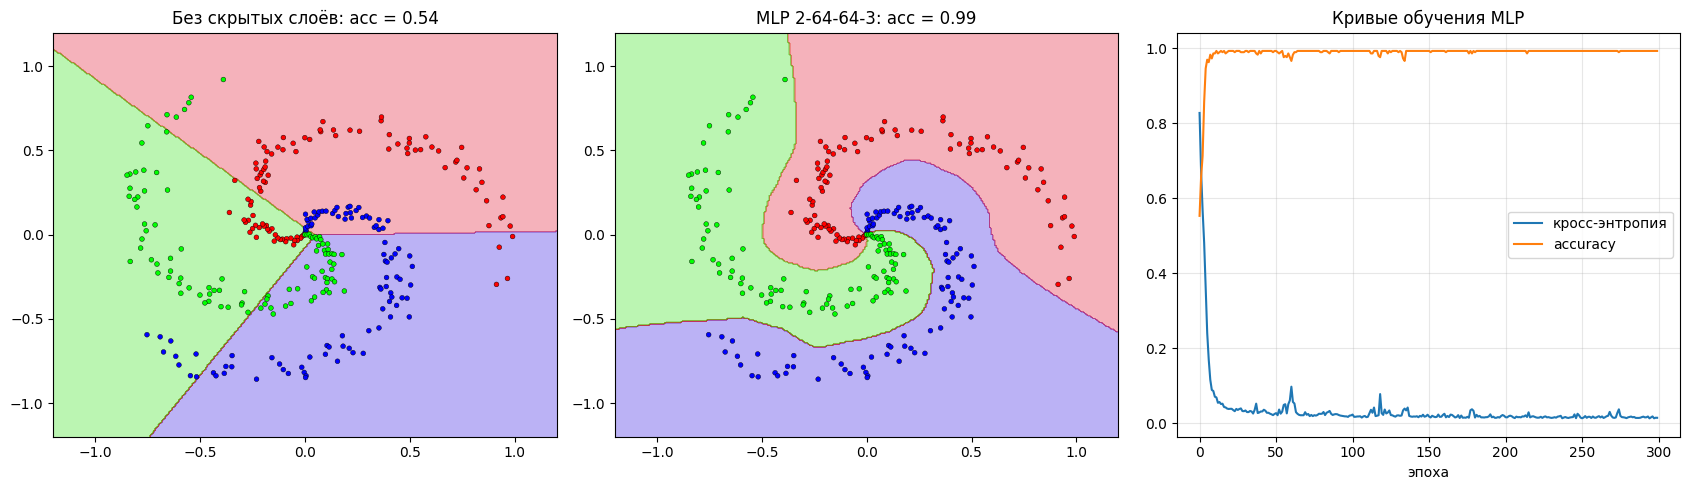

In [39]:
def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    zz = model.predict(grid).numpy().reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap='brg')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='brg', s=12, edgecolor='k', linewidth=0.3)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_boundary(spiral_lin, Xs, ys_, axes[0], f"Без скрытых слоёв: acc = {h_lin['train_acc'][-1]:.2f}")
plot_boundary(spiral_net, Xs, ys_, axes[1], f"MLP 2-64-64-3: acc = {h_sp['train_acc'][-1]:.2f}")
axes[2].plot(h_sp['loss'], label='кросс-энтропия'); axes[2].plot(h_sp['train_acc'], label='accuracy')
axes[2].set_xlabel('эпоха'); axes[2].set_title('Кривые обучения MLP'); axes[2].legend(); axes[2].grid(alpha=.3)
plt.tight_layout()

### 1.3. Распознавание рукописных цифр (sklearn digits)

Набор `digits`: 1797 изображений рукописных цифр 8×8 пикселей (64 признака — яркости пикселей 0…16), 10 классов.
Разделим выборку на обучающую и тестовую (75/25), нормируем яркости на [0, 1].

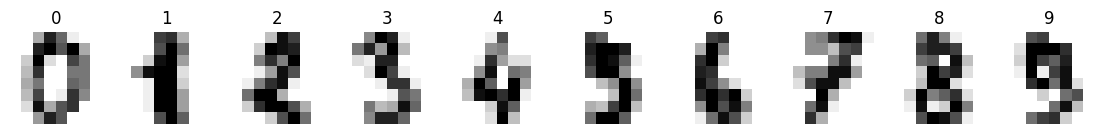

train: (1347, 64)  test: (450, 64)


In [40]:
digits = load_digits()
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, img, lab in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap='gray_r'); ax.set_title(lab); ax.axis('off')
plt.show()

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digits.data / 16.0, digits.target, test_size=0.25,
                                              stratify=digits.target, random_state=42)
Xd_tr, Xd_te = torch.tensor(Xd_tr, dtype=torch.float32), torch.tensor(Xd_te, dtype=torch.float32)
yd_tr, yd_te = torch.tensor(yd_tr), torch.tensor(yd_te)
print('train:', tuple(Xd_tr.shape), ' test:', tuple(Xd_te.shape))

#### Сравнение оптимизаторов (сеть 64-64-10, 60 эпох, batch = 32)

In [41]:
EPOCHS = 60
configs = {
    'SGD (lr=0.05)':                 lambda: SGD(lr=0.05),
    'SGD + momentum (lr=0.05, 0.9)': lambda: SGD(lr=0.05, momentum=0.9),
    'Adam (lr=0.001)':               lambda: Adam(lr=0.001),
}
digit_models, digit_hist, rows = {}, {}, []
for name, make_opt in configs.items():
    torch.manual_seed(0)
    m = MLP([64, 64, 10])
    t0 = time.perf_counter()
    h = m.fit(Xd_tr, yd_tr, make_opt(), epochs=EPOCHS, batch_size=32, X_val=Xd_te, y_val=yd_te)
    dt = time.perf_counter() - t0
    digit_models[name], digit_hist[name] = m, h
    rows.append({'Оптимизатор': name, 'Время, с': round(dt, 2), 'Loss (train)': round(h['loss'][-1], 4),
                 'Accuracy train': round(h['train_acc'][-1], 4), 'Accuracy test': round(h['val_acc'][-1], 4)})
res_opt = pd.DataFrame(rows)
res_opt

,Оптимизатор,"Время, с",Loss (train),Accuracy train,Accuracy test
0,SGD (lr=0.05),0.93,0.0661,0.9889,0.9711
1,"SGD + momentum (lr=0.05, 0.9)",0.93,0.0032,1.0000,0.9733
2,Adam (lr=0.001),1.45,0.0221,0.9993,0.9778


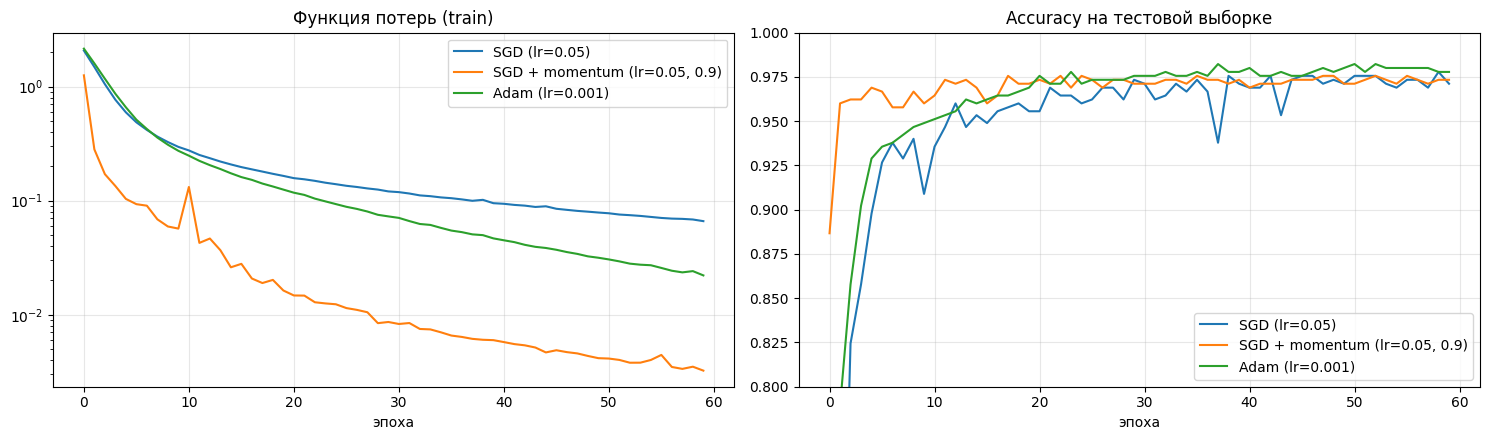

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in digit_hist.items():
    axes[0].plot(h['loss'], label=name); axes[1].plot(h['val_acc'], label=name)
axes[0].set_yscale('log'); axes[0].set_title('Функция потерь (train)'); axes[0].set_xlabel('эпоха'); axes[0].legend()
axes[1].set_title('Accuracy на тестовой выборке'); axes[1].set_xlabel('эпоха'); axes[1].set_ylim(0.8, 1.0); axes[1].legend()
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout()

#### Влияние размера скрытого слоя и глубины сети (Adam, 60 эпох)

In [43]:
rows = []
for sizes in [[64, 10], [64, 16, 10], [64, 32, 10], [64, 64, 10], [64, 128, 10], [64, 128, 64, 10]]:
    torch.manual_seed(0)
    m = MLP(sizes)
    h = m.fit(Xd_tr, yd_tr, Adam(lr=0.001), epochs=EPOCHS, batch_size=32, X_val=Xd_te, y_val=yd_te)
    n_params = sum(l.weights.numel() + l.biases.numel() for l in m.layers if isinstance(l, Dense))
    rows.append({'Архитектура': '-'.join(map(str, sizes)), 'Параметров': n_params,
                 'Accuracy train': round(h['train_acc'][-1], 4), 'Accuracy test': round(h['val_acc'][-1], 4)})
res_arch = pd.DataFrame(rows)
res_arch

,Архитектура,Параметров,Accuracy train,Accuracy test
0,64-10,650,0.9532,0.9422
1,64-16-10,1210,0.9844,0.9667
2,64-32-10,2410,0.9933,0.9756
3,64-64-10,4810,0.9993,0.9778
4,64-128-10,9610,1.0000,0.9800
5,64-128-64-10,17226,1.0000,0.9822


#### Итоговая модель: матрица ошибок и ошибочно распознанные цифры

Accuracy на тесте: 0.9778
              precision    recall  f1-score   support

           0      1.000     0.978     0.989        45
           1      0.900     0.978     0.938        46
           2      1.000     1.000     1.000        44
           3      1.000     1.000     1.000        46
           4      0.957     1.000     0.978        45
           5      1.000     0.978     0.989        46
           6      1.000     0.956     0.977        45
           7      0.978     1.000     0.989        45
           8      0.975     0.907     0.940        43
           9      0.978     0.978     0.978        45

    accuracy                          0.978       450
   macro avg      0.979     0.977     0.978       450
weighted avg      0.979     0.978     0.978       450



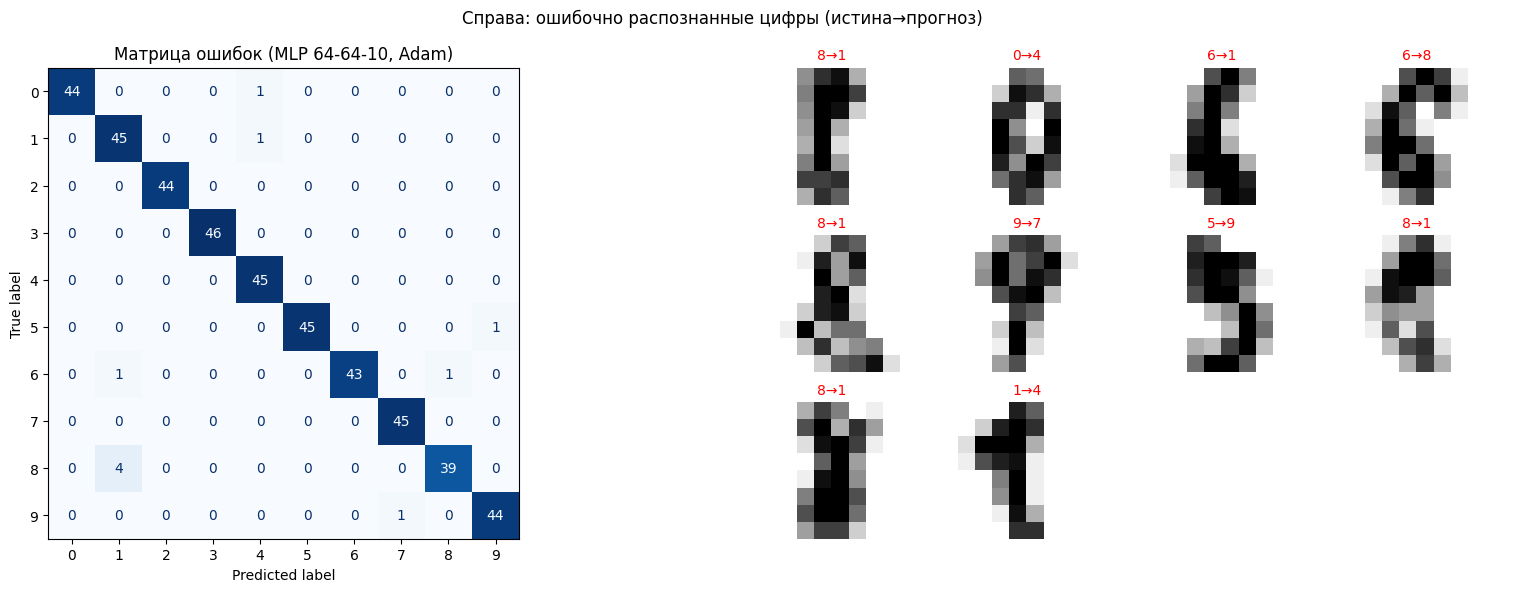

In [44]:
best_digits = digit_models['Adam (lr=0.001)']
pred_te = best_digits.predict(Xd_te).numpy()
print(f'Accuracy на тесте: {accuracy_score(yd_te, pred_te):.4f}')
print(classification_report(yd_te, pred_te, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.3]})
ConfusionMatrixDisplay.from_predictions(yd_te, pred_te, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Матрица ошибок (MLP 64-64-10, Adam)')
wrong = np.where(pred_te != yd_te.numpy())[0][:12]
axes[1].axis('off')
for k, i in enumerate(wrong):
    ax = fig.add_subplot(3, 8, 8 * (k // 4) + 5 + k % 4)
    ax.imshow(Xd_te[i].reshape(8, 8), cmap='gray_r'); ax.axis('off')
    ax.set_title(f'{yd_te[i].item()}→{pred_te[i]}', fontsize=10, color='red')
fig.suptitle('Справа: ошибочно распознанные цифры (истина→прогноз)')
plt.tight_layout()

### 1.4. Та же сеть средствами PyTorch (`torch.nn` + autograd)

Для сравнения обучим сеть той же архитектуры стандартными средствами PyTorch: слои `nn.Linear`, функция потерь `nn.CrossEntropyLoss`,
оптимизатор `torch.optim.Adam`, градиенты вычисляются автоматически.

In [45]:
torch.manual_seed(0)
torch_net = torch.nn.Sequential(torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Linear(64, 10))
opt = torch.optim.Adam(torch_net.parameters(), lr=0.001)
criterion = torch.nn.CrossEntropyLoss()
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    perm = torch.randperm(len(Xd_tr))
    for s in range(0, len(Xd_tr), 32):
        idx = perm[s:s + 32]
        opt.zero_grad()
        loss = criterion(torch_net(Xd_tr[idx]), yd_tr[idx])
        loss.backward()
        opt.step()
t_torch = time.perf_counter() - t0
with torch.no_grad():
    acc_torch = (torch_net(Xd_te).argmax(1) == yd_te).float().mean().item()
cmp = pd.DataFrame([
    {'Реализация': 'Собственная (ручной backward)', 'Время, с': res_opt.loc[2, 'Время, с'], 'Accuracy test': res_opt.loc[2, 'Accuracy test']},
    {'Реализация': 'PyTorch nn + autograd', 'Время, с': round(t_torch, 2), 'Accuracy test': round(acc_torch, 4)},
])
cmp

,Реализация,"Время, с",Accuracy test
0,Собственная (ручной backward),1.45,0.9778
1,PyTorch nn + autograd,1.33,0.9756


### 1.5. Регрессия: аппроксимация функции $y = \sin(x)$

В примере сеть аппроксимировала параболу. Проверим, как сеть с одним скрытым слоем аппроксимирует более сложную функцию
$y = \sin(x)$ на $[-\pi, \pi]$ с шумом, в зависимости от числа нейронов (используются классы `Dense`, `Activation_ReLU`, `MSELoss` из примера).

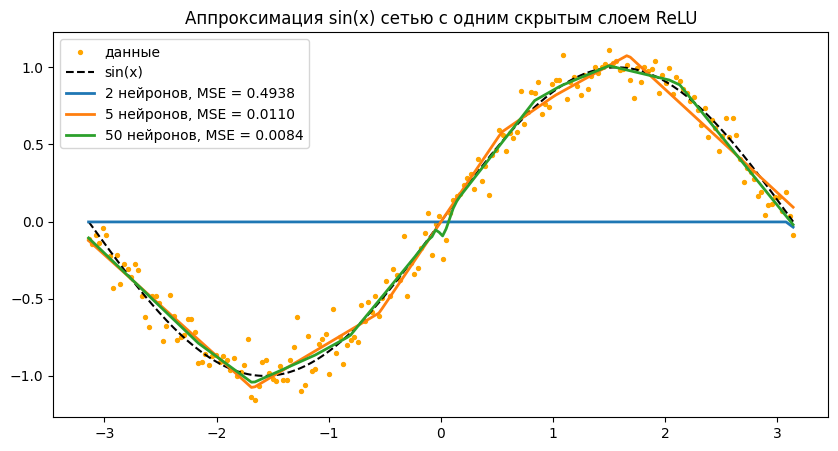

In [46]:
torch.manual_seed(0)
Xr = torch.linspace(-np.pi, np.pi, 200).view(-1, 1)
yr = torch.sin(Xr) + 0.1 * torch.randn(Xr.size())

def fit_regression(n_hidden, epochs=3000, lr=0.01):
    torch.manual_seed(0)
    f1, act, f2 = Dense(1, n_hidden), Activation_ReLU(), Dense(n_hidden, 1)
    mse, opt = MSELoss(), Adam(lr=lr)
    for _ in range(epochs):
        out = f2.forward(act.forward(f1.forward(Xr)))
        mse.backward(out, yr)
        act.backward(f2.backward(mse.dinputs))
        f1.backward(act.dinputs)
        opt.step([f1, f2])
    out = f2.forward(act.forward(f1.forward(Xr)))
    return out, mse.calculate(out, yr).item()

plt.figure(figsize=(10, 5))
plt.scatter(Xr, yr, s=8, c='orange', label='данные')
plt.plot(Xr, torch.sin(Xr), 'k--', label='sin(x)')
for n_hidden in [2, 5, 50]:
    out, l = fit_regression(n_hidden)
    plt.plot(Xr, out, lw=2, label=f'{n_hidden} нейронов, MSE = {l:.4f}')
plt.legend(); plt.title('Аппроксимация sin(x) сетью с одним скрытым слоем ReLU'); plt.show()

## Часть 2. Кластеризация k-means и k-means++

Тема практического занятия в заголовке методических указаний — кластеризация **k-means** и **k-means++**. Реализуем оба алгоритма.

**k-means** (алгоритм Ллойда) разбивает выборку на $k$ кластеров, минимизируя сумму квадратов расстояний до центров (инерцию)
$J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \|x_i - \mu_j\|^2$:
1. выбрать начальные центры;
2. отнести каждую точку к ближайшему центру;
3. пересчитать центры как средние точек кластеров;
4. повторять шаги 2–3, пока центры меняются.

Результат зависит от начальных центров. При **случайной** инициализации (k случайных точек) алгоритм часто застревает в плохом
локальном минимуме. **k-means++** выбирает первый центр случайно, а каждый следующий — с вероятностью, пропорциональной
квадрату расстояния до ближайшего уже выбранного центра $D(x)^2$, поэтому центры получаются «разнесёнными» по данным.

In [47]:
from sklearn.datasets import load_iris, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score


class KMeansCustom:
    def __init__(self, n_clusters=3, init='k-means++', n_init=1, max_iter=300, tol=1e-6, random_state=None):
        self.k, self.init, self.n_init, self.max_iter, self.tol = n_clusters, init, n_init, max_iter, tol
        self.rng = np.random.default_rng(random_state)

    def _init_centers(self, X):
        if self.init == 'random':
            return X[self.rng.choice(len(X), self.k, replace=False)].copy()
        centers = [X[self.rng.integers(len(X))]]                       # k-means++
        for _ in range(1, self.k):
            d2 = ((X[:, None, :] - np.array(centers)[None]) ** 2).sum(-1).min(axis=1)
            centers.append(X[self.rng.choice(len(X), p=d2 / d2.sum())])
        return np.array(centers)

    def fit(self, X):
        """n_init запусков с разными начальными центрами, сохраняется решение с наименьшей инерцией."""
        X = np.asarray(X, dtype=float)
        best = None
        for _ in range(self.n_init):
            self._single_run(X)
            if best is None or self.inertia_ < best[0]:
                best = (self.inertia_, self.centers_, self.labels_, self.n_iter_)
        self.inertia_, self.centers_, self.labels_, self.n_iter_ = best
        return self

    def _single_run(self, X):
        self.centers_ = self._init_centers(X)
        for it in range(1, self.max_iter + 1):
            dist = ((X[:, None, :] - self.centers_[None]) ** 2).sum(-1)
            self.labels_ = dist.argmin(axis=1)
            new = np.array([X[self.labels_ == j].mean(0) if np.any(self.labels_ == j) else self.centers_[j]
                            for j in range(self.k)])
            shift = np.abs(new - self.centers_).max()
            self.centers_ = new
            if shift < self.tol:
                break
        self.n_iter_ = it
        self.inertia_ = ((X - self.centers_[self.labels_]) ** 2).sum()

    def predict(self, X):
        return ((np.asarray(X)[:, None, :] - self.centers_[None]) ** 2).sum(-1).argmin(axis=1)

### 2.1. Кластеризация ирисов Фишера, выбор числа кластеров

Силуэт по k: {2: np.float64(0.582), 3: np.float64(0.46), 4: np.float64(0.387), 5: np.float64(0.346), 6: np.float64(0.339), 7: np.float64(0.339), 8: np.float64(0.32), 9: np.float64(0.353), 10: np.float64(0.348)}


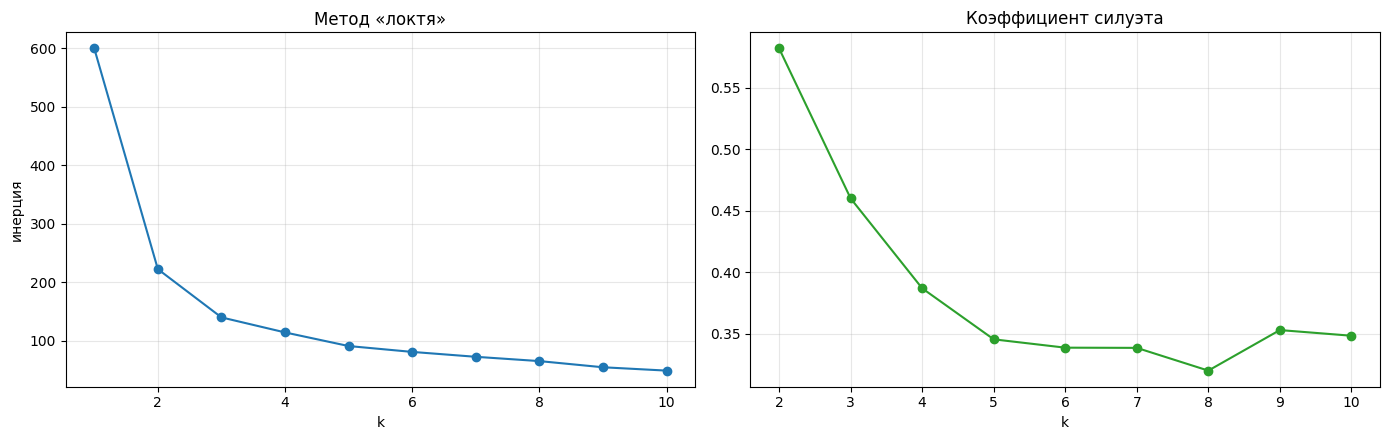

In [48]:
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data)
ks = range(1, 11)
fits = {k: KMeansCustom(k, n_init=10, random_state=0).fit(Xi) for k in ks}
inertias = [fits[k].inertia_ for k in ks]
sils = [silhouette_score(Xi, fits[k].labels_) for k in ks[1:]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ks, inertias, 'o-'); axes[0].set_xlabel('k'); axes[0].set_ylabel('инерция'); axes[0].set_title('Метод «локтя»')
axes[1].plot(list(ks)[1:], sils, 'o-', c='tab:green'); axes[1].set_xlabel('k'); axes[1].set_title('Коэффициент силуэта')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout()
print('Силуэт по k:', dict(zip(list(ks)[1:], np.round(sils, 3))))

Собственная реализация (n_init=10): инерция = 139.820, итераций = 4, ARI с истинными видами = 0.620
sklearn KMeans:         инерция = 139.820, ARI = 0.620
кластер      0   1   2
вид                   
setosa      50   0   0
versicolor   0  39  11
virginica    0  14  36


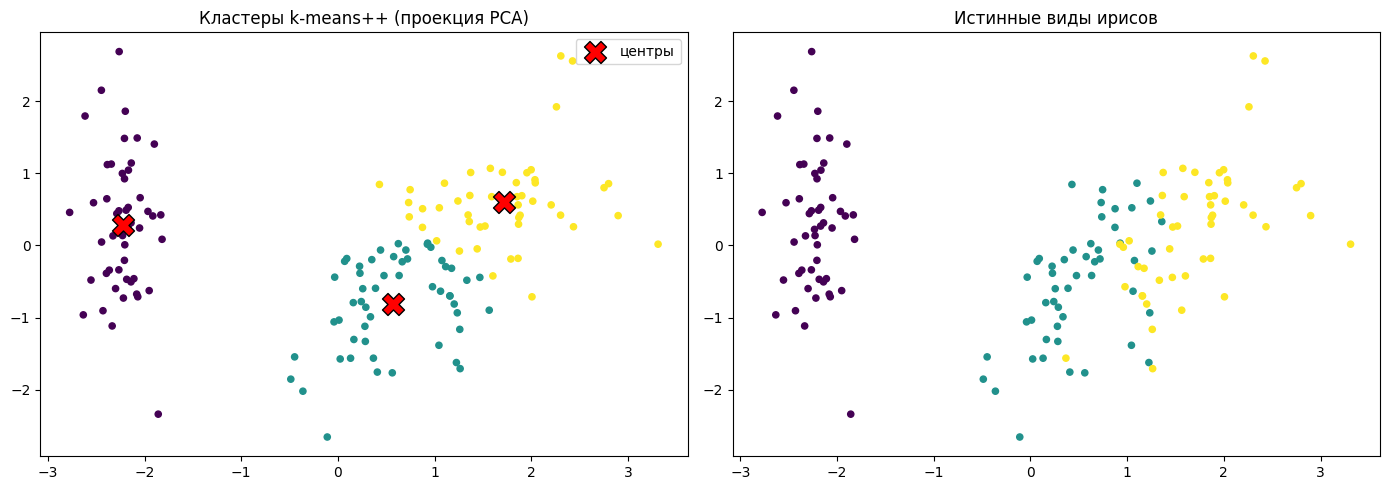

In [49]:
km = KMeansCustom(3, init='k-means++', n_init=10, random_state=0).fit(Xi)
sk = KMeans(3, init='k-means++', n_init=10, random_state=0).fit(Xi)
print(f'Собственная реализация (n_init=10): инерция = {km.inertia_:.3f}, итераций = {km.n_iter_}, ARI с истинными видами = {adjusted_rand_score(iris.target, km.labels_):.3f}')
print(f'sklearn KMeans:         инерция = {sk.inertia_:.3f}, ARI = {adjusted_rand_score(iris.target, sk.labels_):.3f}')
print(pd.crosstab(pd.Series(iris.target_names[iris.target], name='вид'), pd.Series(km.labels_, name='кластер')))

pca = PCA(2).fit(Xi)
P, C = pca.transform(Xi), pca.transform(km.centers_)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(P[:, 0], P[:, 1], c=km.labels_, cmap='viridis', s=20)
axes[0].scatter(C[:, 0], C[:, 1], c='red', marker='X', s=250, edgecolor='k', label='центры')
axes[0].set_title('Кластеры k-means++ (проекция PCA)'); axes[0].legend()
axes[1].scatter(P[:, 0], P[:, 1], c=iris.target, cmap='viridis', s=20); axes[1].set_title('Истинные виды ирисов')
plt.tight_layout()

### 2.2. Сравнение случайной инициализации и k-means++

Сгенерируем 8 хорошо разделимых кластеров и запустим алгоритм 200 раз с разными начальными центрами (каждый раз одна инициализация,
`n_init = 1`). Оптимальное решение известно: каждая группа точек — отдельный кластер.

In [50]:
Xb, yb = make_blobs(n_samples=800, centers=8, cluster_std=0.6, random_state=7)
rows, best = [], {}
for init in ['random', 'k-means++']:
    runs = [KMeansCustom(8, init=init, random_state=s).fit(Xb) for s in range(200)]
    inert = np.array([r.inertia_ for r in runs]); its = np.array([r.n_iter_ for r in runs])
    ari = np.array([adjusted_rand_score(yb, r.labels_) for r in runs])
    best[init] = runs[int(np.argmax(inert))]   # худший запуск — для иллюстрации
    rows.append({'Инициализация': init, 'Инерция: среднее': inert.mean().round(1), 'Инерция: минимум': inert.min().round(1),
                 'Инерция: максимум': inert.max().round(1), 'Доля оптимальных решений': np.mean(ari > 0.99).round(3),
                 'Итераций (среднее)': its.mean().round(1)})
res_km = pd.DataFrame(rows)
res_km

,Инициализация,Инерция: среднее,Инерция: минимум,Инерция: максимум,Доля оптимальных решений,Итераций (среднее)
0,random,1950.2,554.8,7137.9,0.120,9.1
1,k-means++,807.8,554.8,2864.3,0.535,5.6


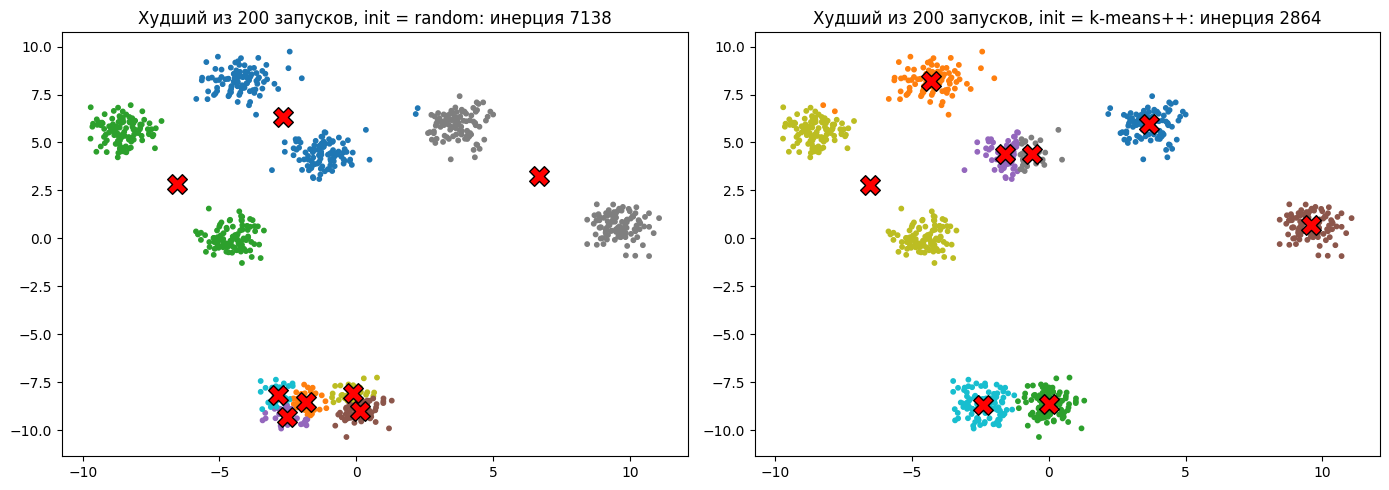

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, init in zip(axes, ['random', 'k-means++']):
    r = best[init]
    ax.scatter(Xb[:, 0], Xb[:, 1], c=r.labels_, cmap='tab10', s=10)
    ax.scatter(r.centers_[:, 0], r.centers_[:, 1], c='red', marker='X', s=200, edgecolor='k')
    ax.set_title(f'Худший из 200 запусков, init = {init}: инерция {r.inertia_:.0f}')
plt.tight_layout()

## Выводы

1. Реализованы основные элементы нейронной сети на тензорах PyTorch: нейрон, полносвязный слой, функции активации ReLU и softmax,
   функции потерь MSE и категориальная кросс-энтропия, обучение стохастическим градиентным спуском. Собственная реализация
   **обратного распространения ошибки** проверена сравнением с автоматическим дифференцированием PyTorch: градиенты совпадают
   с точностью до ошибок округления (расхождение ≈ 1e-17).
2. Модель без скрытых слоёв не может разделить «спирали» (accuracy 0.54), а многослойный персептрон 2-64-64-3 строит
   нелинейную разделяющую границу и достигает accuracy 0.99: скрытые слои с нелинейной активацией позволяют сети
   аппроксимировать сложные зависимости.
3. На задаче распознавания рукописных цифр персептрон 64-64-10 достигает accuracy 0.978 на тестовой выборке (Adam);
   SGD — 0.971, SGD с инерцией — 0.973. Инерция и адаптивный шаг ускоряют сходимость: за 60 эпох SGD + momentum
   снижает функцию потерь в 20 раз сильнее обычного SGD. Расширение скрытого слоя с 16 до 128 нейронов повышает accuracy
   с 0.967 до 0.980, второй скрытый слой даёт 0.982; модель без скрытого слоя — 0.942. Собственная реализация по качеству
   не уступает сети на `torch.nn` с автоматическим дифференцированием (0.978 против 0.976) при сопоставимом времени.
4. При аппроксимации sin(x) сеть с 50 нейронами повторяет функцию с MSE 0.0084 — на уровне дисперсии шума (0.01),
   сеть с 5 нейронами даёт грубую кусочно-линейную кривую (MSE 0.011). Сеть с 2 нейронами выдала константу (MSE 0.49):
   оба нейрона ReLU «умерли» — их вход стал отрицательным для всех точек, градиент через них равен нулю и обучение
   остановилось. Это известная проблема **«умирающих ReLU»**, особенно заметная в узких сетях.
5. Реализованы алгоритмы кластеризации k-means и k-means++. На ирисах Фишера максимум силуэта достигается при k = 2
   (setosa против остальных), при k = 3 setosa выделяется безошибочно, а versicolor и virginica частично смешиваются;
   результат собственной реализации совпадает с sklearn KMeans.
6. Инициализация **k-means++** существенно надёжнее случайной: на данных с 8 кластерами она находит оптимальное разбиение
   в 53.5 % запусков против 12 % у случайной, средняя инерция ниже в 2.4 раза (808 против 1950), а сходимость быстрее
   (5.6 против 9.1 итерации). На практике k-means++ дополнительно сочетают с несколькими перезапусками (`n_init`).